# Module 8 practice – charts for the ShopKart team

**Video 8.2–8.3 (practice)** · ShopKart project

**Goal:** Practise choosing the right chart and making it clear. 5 tasks.

**How to open in Colab:** go to colab.research.google.com → File → Upload notebook → choose this file. Then click the folder icon on the left and drag these data files in: `shopkart_clean.csv`. Then run cells from top to bottom (Shift + Enter).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("shopkart_clean.csv")
MAIN, HIGHLIGHT, GREY = "#2a78d6", "#eb6834", "#b8b6ae"

### Task 1
The marketing team asks: **which payment mode is used most?** Pick the right chart, sort it, add a message title.

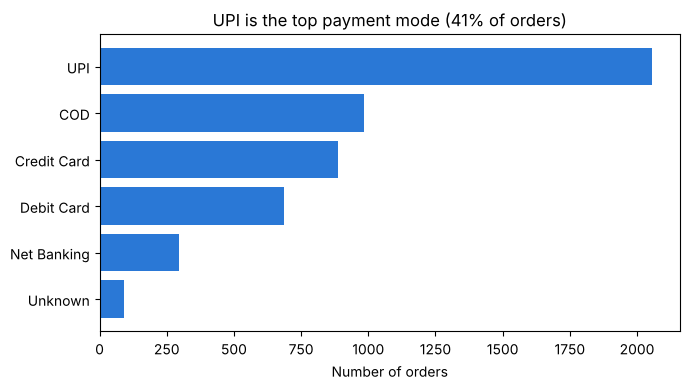

payment_mode
UPI            2057
COD             983
Credit Card     888
Debit Card      685
Net Banking     297
Unknown          90
Name: count, dtype: int64

In [2]:
pay = df["payment_mode"].value_counts().sort_values()
plt.figure(figsize=(7, 4))
plt.barh(pay.index, pay.values, color=MAIN)
plt.title(f"UPI is the top payment mode ({pay['UPI'] / len(df) * 100:.0f}% of orders)")
plt.xlabel("Number of orders")
plt.tight_layout(); plt.show()
pay.sort_values(ascending=False)

### Task 2
**Monthly profit trend.** Line chart of total profit by `order_month`, y-axis starting at 0. Which month has the highest profit?

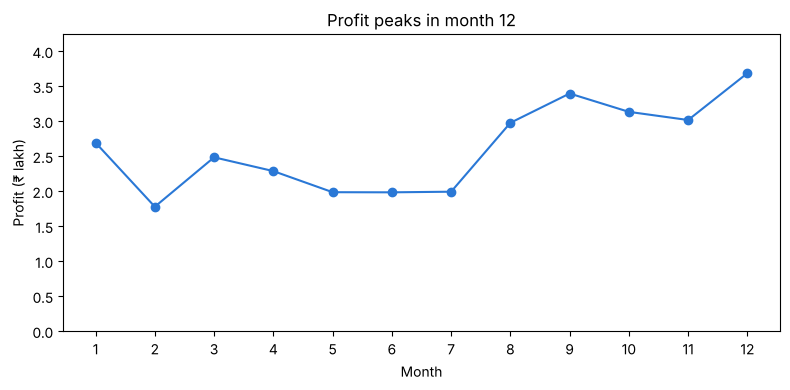

Highest-profit month: 12 with ₹ 3.69 lakh


In [3]:
mp = df.groupby("order_month")["profit"].sum() / 100000
plt.figure(figsize=(8, 4))
plt.plot(mp.index, mp.values, marker="o", color=MAIN)
plt.ylim(0, mp.max() * 1.15)
plt.xticks(range(1, 13))
plt.title(f"Profit peaks in month {mp.idxmax()}")
plt.xlabel("Month"); plt.ylabel("Profit (₹ lakh)")
plt.tight_layout(); plt.show()
print("Highest-profit month:", mp.idxmax(), "with ₹", round(mp.max(), 2), "lakh")

### Task 3
**Age of customers per order.** Histogram of `age` with 20 bins. What is the most common age range?

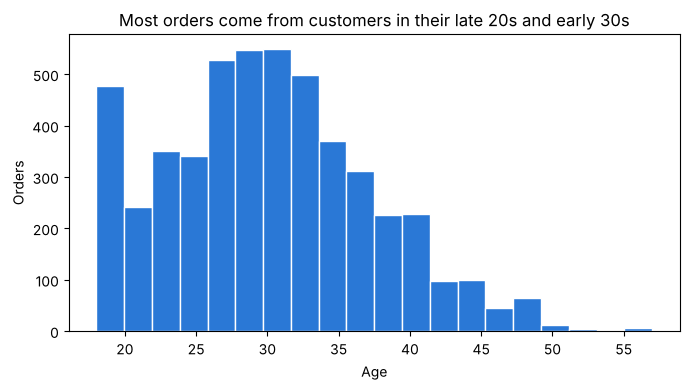

Median age: 30.0 | middle 50%: 24.0 to 34.0


In [4]:
plt.figure(figsize=(7, 4))
plt.hist(df["age"], bins=20, color=MAIN, edgecolor="white")
plt.title("Most orders come from customers in their late 20s and early 30s")
plt.xlabel("Age"); plt.ylabel("Orders")
plt.tight_layout(); plt.show()
print("Median age:", df["age"].median(), "| middle 50%:", df["age"].quantile(0.25), "to", df["age"].quantile(0.75))

### Task 4
**Does payment mode affect returns?** Bar chart of return rate (%) by payment mode, highlight the highest bar.

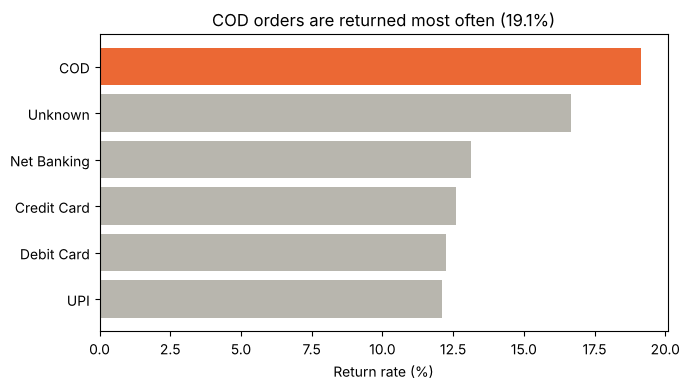

payment_mode
COD            19.1
Unknown        16.7
Net Banking    13.1
Credit Card    12.6
Debit Card     12.3
UPI            12.1
Name: returned, dtype: float64

In [5]:
rr = (df["returned"].eq("Y").groupby(df["payment_mode"]).mean() * 100).sort_values()
plt.figure(figsize=(7, 4))
plt.barh(rr.index, rr.values, color=[HIGHLIGHT if v == rr.max() else GREY for v in rr.values])
plt.title(f"{rr.idxmax()} orders are returned most often ({rr.max():.1f}%)")
plt.xlabel("Return rate (%)")
plt.tight_layout(); plt.show()
rr.round(1).sort_values(ascending=False)

### Task 5
Rewrite these titles as **message titles** using real numbers you compute:
1. "Revenue by Category"
2. "Orders by Membership"

In [6]:
cat_share = df.groupby("category")["revenue"].sum() / df["revenue"].sum() * 100
mem = df.groupby("membership").agg(orders=("order_id", "count"), customers=("customer_id", "nunique"))
mem["orders_per_customer"] = (mem["orders"] / mem["customers"]).round(1)
print(f"1. Electronics brings {cat_share['Electronics']:.0f}% of all revenue")
print(f"2. Prime customers order about {mem.loc['Prime','orders_per_customer'] / mem.loc['Free','orders_per_customer']:.0f}x as often as Free customers")
mem

1. Electronics brings 50% of all revenue
2. Prime customers order about 2x as often as Free customers


,orders,customers,orders_per_customer
membership,,,
Free,2298,482,4.8
Prime,2702,276,9.8
